In [1]:
ROLL_NO = 1024171337
NAME = "meet-the-1337"
BRANCH = "COPC"

import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("Roll Number:", ROLL_NO)
print("Name:", NAME)
print("Branch:", BRANCH)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Roll Number: 1024171337
Name: meet-the-1337
Branch: COPC


Original text:
I enjoy learning about technology and programming.
Computer science allows people to solve real world problems.
I like building software projects and learning new programming languages.
Python is useful for data analysis and artificial intelligence.
Reading technical books helps me understand complex ideas.
Technology continues to change the way people learn and communicate.

Cleaned text:
i enjoy learning about technology and programming
computer science allows people to solve real world problems
i like building software projects and learning new programming languages
python is useful for data analysis and artificial intelligence
reading technical books helps me understand complex ideas
technology continues to change the way people learn and communicate

Sentences:
['I enjoy learning about technology and programming.', 'Computer science allows people to solve real world problems.', 'I like building software projects and learning new programming languages.', 'Python is u

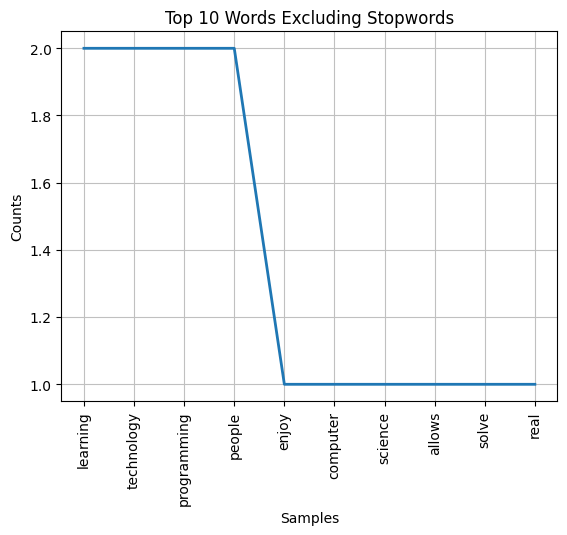

In [2]:
text = """I enjoy learning about technology and programming.
Computer science allows people to solve real world problems.
I like building software projects and learning new programming languages.
Python is useful for data analysis and artificial intelligence.
Reading technical books helps me understand complex ideas.
Technology continues to change the way people learn and communicate."""

clean_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', clean_text)

print("Original text:")
print(text)

print("\nCleaned text:")
print(clean_text)

sentences = sent_tokenize(text)
print("\nSentences:")
print(sentences)

tokens_split = clean_text.split()
tokens_nltk = word_tokenize(clean_text)

print("\nUsing split():")
print(tokens_split)

print("\nUsing word_tokenize():")
print(tokens_nltk)

print("\nNumber of tokens using split():", len(tokens_split))
print("Number of tokens using word_tokenize():", len(tokens_nltk))

filtered_words = [word for word in tokens_nltk if word not in stop_words]

print("\nAfter removing stopwords:")
print(filtered_words)

from nltk.probability import FreqDist

freq = FreqDist(filtered_words)

print("\nWord frequency distribution:")
print(freq.most_common())

freq.plot(10, title="Top 10 Words Excluding Stopwords")
plt.show()

split() separates text wherever whitespace occurs, while word_tokenize() uses NLTK's tokenizer to handle word boundaries and punctuation more carefully. In this example, punctuation is removed before tokenization, so their outputs may be similar.

In [3]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Words containing only alphabets:")
print(words)

filtered_words = [word for word in words if word not in stop_words]

print("\nAfter removing stopwords:")
print(filtered_words)

porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [porter.stem(word) for word in filtered_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

q2_df = pd.DataFrame({
    "Original Word": filtered_words,
    "Stemmed Word": stemmed_words,
    "Lemmatized Word": lemmatized_words
})

print("\nComparison:")
print(q2_df)

Words containing only alphabets:
['i', 'enjoy', 'learning', 'about', 'technology', 'and', 'programming', 'computer', 'science', 'allows', 'people', 'to', 'solve', 'real', 'world', 'problems', 'i', 'like', 'building', 'software', 'projects', 'and', 'learning', 'new', 'programming', 'languages', 'python', 'is', 'useful', 'for', 'data', 'analysis', 'and', 'artificial', 'intelligence', 'reading', 'technical', 'books', 'helps', 'me', 'understand', 'complex', 'ideas', 'technology', 'continues', 'to', 'change', 'the', 'way', 'people', 'learn', 'and', 'communicate']

After removing stopwords:
['enjoy', 'learning', 'technology', 'programming', 'computer', 'science', 'allows', 'people', 'solve', 'real', 'world', 'problems', 'like', 'building', 'software', 'projects', 'learning', 'new', 'programming', 'languages', 'python', 'useful', 'data', 'analysis', 'artificial', 'intelligence', 'reading', 'technical', 'books', 'helps', 'understand', 'complex', 'ideas', 'technology', 'continues', 'change', 'w

Stemming removes word endings using simple rules, so it may produce words that are not grammatically correct. Lemmatization converts words to their dictionary form and usually produces meaningful words. Stemming is useful when speed is important, such as in search systems, while lemmatization is preferable when the meaning and grammatical form of words matter

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn from data and make predictions.",
    "Machine learning is used in artificial intelligence to analyze data.",
    "Cybersecurity protects computers, networks and data from digital attacks."
]

count_vectorizer = CountVectorizer()
bow = count_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("Bag of Words:")
print(bow_df)

tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("\nTF-IDF scores:")
print(tfidf_df.round(3))

features = tfidf_vectorizer.get_feature_names_out()

for i in range(len(texts)):
    scores = tfidf.toarray()[i]
    top_indices = scores.argsort()[-3:][::-1]

    print("\nTop 3 keywords in Text", i + 1, ":")
    for index in top_indices:
        print(features[index], round(scores[index], 3))

Bag of Words:
        analyze  and  artificial  attacks  computers  cybersecurity  data  \
Text 1        0    1           1        0          1              0     1   
Text 2        1    0           1        0          0              0     1   
Text 3        0    1           0        1          1              1     1   

        digital  from  helps  ...  is  learn  learning  machine  make  \
Text 1        0     1      1  ...   0      1         0        0     1   
Text 2        0     0      0  ...   1      0         1        1     0   
Text 3        1     1      0  ...   0      0         0        0     0   

        networks  predictions  protects  to  used  
Text 1         0            1         0   0     0  
Text 2         0            0         0   1     1  
Text 3         1            0         1   0     0  

[3 rows x 22 columns]

TF-IDF scores:
        analyze    and  artificial  attacks  computers  cybersecurity   data  \
Text 1    0.000  0.283       0.283    0.000      0.283   

Bag of Words represents each text by counting how often each word appears. TF-IDF assigns greater importance to words that are relatively distinctive to a text and lower importance to words common across the collection. Therefore, the top TF-IDF keywords help identify the main topics of each text.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables machines to learn from data.
It helps systems recognize patterns and make predictions.
AI is used in healthcare, education and automation.
Machine learning is an important part of AI.
These systems can improve through training and feedback."""

text2 = """Blockchain stores information in linked digital blocks.
It provides a distributed and tamper resistant ledger.
Blockchain is used in cryptocurrency and supply chain systems.
Transactions are recorded across a network.
Cryptographic techniques help maintain data integrity."""

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens in Text 1:")
print(tokens1)

print("\nTokens in Text 2:")
print(tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("\nJaccard Similarity:", round(jaccard, 3))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 3))

Tokens in Text 1:
['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'helps', 'systems', 'recognize', 'patterns', 'make', 'predictions', 'ai', 'used', 'healthcare', 'education', 'automation', 'machine', 'learning', 'important', 'part', 'ai', 'systems', 'improve', 'training', 'feedback']

Tokens in Text 2:
['blockchain', 'stores', 'information', 'linked', 'digital', 'blocks', 'provides', 'distributed', 'tamper', 'resistant', 'ledger', 'blockchain', 'used', 'cryptocurrency', 'supply', 'chain', 'systems', 'transactions', 'recorded', 'across', 'network', 'cryptographic', 'techniques', 'help', 'maintain', 'data', 'integrity']

Jaccard Similarity: 0.064
Cosine Similarity: 0.203


Jaccard similarity compares the intersection and union of the unique words in both texts. Cosine similarity compares their TF-IDF vectors and considers the importance of words. In this example, both texts discuss technology but focus on different subjects. Jaccard similarity is useful for comparing shared vocabulary, while cosine similarity can provide more informative comparisons when distinctive terms have different importance.

                                              Review  Polarity  Subjectivity  \
0  This laptop is excellent and works very smoothly.     0.760         0.825   
1  The product is amazing and the battery life is...     0.700         0.825   
2              I am very happy with the performance.     1.000         1.000   
3  The service was terrible and the product stopp...    -1.000         1.000   
4  Very poor quality and disappointing customer s...    -0.560         0.740   
5      The application is slow and difficult to use.    -0.400         0.700   
6                         The product arrived today.     0.000         0.000   
7             The service was okay, nothing special.     0.429         0.536   
8           The package contains the expected items.    -0.100         0.400   

  Sentiment  
0  Positive  
1  Positive  
2  Positive  
3  Negative  
4  Negative  
5  Negative  
6   Neutral  
7  Positive  
8  Negative  


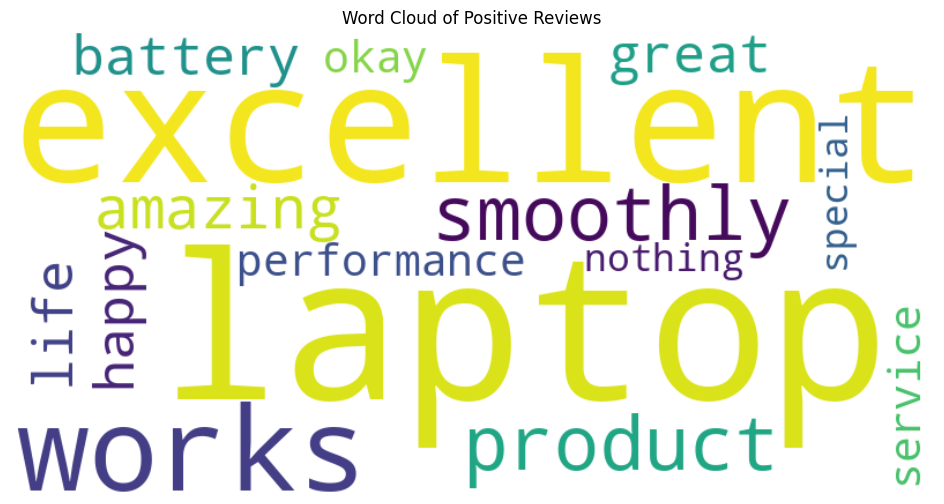

In [6]:
from textblob import TextBlob
from wordcloud import WordCloud, STOPWORDS

reviews = [
    "This laptop is excellent and works very smoothly.",
    "The product is amazing and the battery life is great.",
    "I am very happy with the performance.",
    "The service was terrible and the product stopped working.",
    "Very poor quality and disappointing customer support.",
    "The application is slow and difficult to use.",
    "The product arrived today.",
    "The service was okay, nothing special.",
    "The package contains the expected items."
]

results = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append({
        "Review": review,
        "Polarity": round(polarity, 3),
        "Subjectivity": round(subjectivity, 3),
        "Sentiment": sentiment
    })

reviews_df = pd.DataFrame(results)

print(reviews_df)

positive_reviews = reviews_df[
    reviews_df["Sentiment"] == "Positive"
]["Review"]

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    stopwords=STOPWORDS
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()

Polarity measures whether a review expresses positive or negative sentiment, while subjectivity measures the extent to which it expresses opinions rather than objective facts. Reviews are classified as positive when polarity is above zero, negative when below zero, and neutral when equal to zero. The word cloud displays frequently occurring words in the positive reviews.

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

training_text = """Technology plays an important role in modern life.
Computers help people solve problems and process information.
Programming allows developers to create applications and useful tools.
Machine learning enables computers to learn patterns from data.
Artificial intelligence is used in healthcare education and research.
Software engineers design systems that are reliable and efficient.
Learning new concepts requires patience practice and consistency.
Reading documentation helps programmers understand complex systems.
Open source projects allow developers to collaborate and share knowledge.
Every project provides an opportunity to learn something new.
Good software requires testing debugging and careful planning.
Technology continues to evolve and create new opportunities.
Students can improve their skills by building practical projects.
Regular practice helps people become better problem solvers.
Curiosity and creativity are important qualities for every developer."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

sequences = []

for line in training_text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequences.append(token_list[:i + 1])

max_sequence_len = max(len(sequence) for sequence in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

y = to_categorical(y, num_classes=total_words)

model = Sequential()
model.add(Embedding(total_words, 32))
model.add(LSTM(64))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

model.fit(X, y, epochs=100, verbose=0)

print("Model training completed.")

def generate_text(seed_text, next_words=12):
    output_text = seed_text

    for i in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted, axis=1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break

        if output_word == "":
            break

        output_text += " " + output_word

    return output_text

print("\nGenerated text 1:")
print(generate_text("technology", 12))

print("\nGenerated text 2:")
print(generate_text("programming", 12))

print("\nGenerated text 3:")
print(generate_text("software", 12))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Model training completed.

Generated text 1:
technology continues to to create and new opportunities developer developer developer developer developer

Generated text 2:
programming helps people people become complex and information data developer developer developer developer

Generated text 3:
software continues requires requires and and careful planning knowledge developer developer developer developer


The LSTM model learns patterns and word sequences from the training paragraph. The text is converted into numerical sequences, which are used to train the model to predict the next word. Text generation starts with a seed word, and the model repeatedly predicts additional words to produce new text.

Because the training dataset is small, the generated text may repeat words or lack grammatical correctness. A larger and more varied dataset would generally help improve the results.